# Thực nghiệm 3: Thử tham số C cho Logistic Regression

Thực nghiệm Logistic Regression trên tập A gồm 3.539 mẫu và 36 đặc trưng, thử tăng tham số C từ 0.1 lên 0.5, để kiểm tra khả năng cải thiện mô hình. Hai cấu hình được đánh giá bằng Stratified 5-fold CV với chỉ số Macro-F1. Kết quả được lưu dưới dạng Excel, CSV và biểu đồ trong thư mục thực nghiệm.

## 1. Cấu hình và tham số

In [7]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

cwd = Path.cwd().resolve()
project_dir = next(
    (p for p in (cwd, *cwd.parents, cwd / "ML01_Student_Dropout")
     if (p / "feature_b" / "common.py").is_file()
     and (p / "data" / "processed" / "development.csv").is_file()),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy project ML01_Student_Dropout. "
        "Hãy mở đúng thư mục dự án trong VS Code rồi Run All."
    )

sys.path.insert(0, str(project_dir / "feature_b"))
from common import evaluate, load_development

output_dir = project_dir / "experiments" / "2026-11-13_ThuThamSo_LR_Ly"
data_path = project_dir / "data" / "processed" / "development.csv"
N_FOLDS = 5
SEED = 42

configs = {
    "LR goc (C=0.1)": {"C": 0.1, "class_weight": "balanced", "solver": "lbfgs", "max_iter": 3000},
    "LR thu (C=0.5)": {"C": 0.5, "class_weight": "balanced", "solver": "lbfgs", "max_iter": 3000},
}
print("Project:", project_dir)
print("Output:", output_dir)
print("sklearn:", sklearn.__version__)
display(pd.DataFrame([{"Cau hinh": name, **params} for name, params in configs.items()]))

Project: C:\doan\sgu-MAYHOC\ML01_Student_Dropout
Output: C:\doan\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-13_ThuThamSo_LR_Ly
sklearn: 1.8.0


,Cau hinh,C,class_weight,solver,max_iter
0,LR goc (C=0.1),0.1,balanced,lbfgs,3000
1,LR thu (C=0.5),0.5,balanced,lbfgs,3000


## 2. Huấn luyện và đánh giá hai cấu hình Logistic Regression

In [8]:
X_a, _, y = load_development(data_path)
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_a, y))

summary_rows = []
fold_tables = []
for name, params in configs.items():
    print(f"Đang đánh giá: {name}")
    model = LogisticRegression(**params)
    summary, fold_scores = evaluate(name, model, True, "A", X_a, y, folds)
    summary_rows.append({**summary, "C": params["C"]})
    fold_tables.append(fold_scores)

results = pd.DataFrame(summary_rows)
fold_results = pd.concat(fold_tables, ignore_index=True)
old_score = results.loc[results["C"].eq(0.1), "cv_macro_f1"].iloc[0]
new_score = results.loc[results["C"].eq(0.5), "cv_macro_f1"].iloc[0]
delta = new_score - old_score

print(f"\nC=0.1 : {old_score:.6f}")
print(f"C=0.5: {new_score:.6f}")
print(f"Chênh lệch (mới - cũ): {delta:+.6f}")
if delta > 0:
    print("Nhận xét: Trong lần đánh giá này, C=0.5 có CV Macro-F1 cao hơn.")
elif delta < 0:
    print("Nhận xét: Trong lần đánh giá này, C=0.1 có CV Macro-F1 cao hơn.")
else:
    print("Nhận xét: Hai cấu hình có cùng CV Macro-F1.")
display(results.round(6))
display(fold_results.round(6))

3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang đánh giá: LR goc (C=0.1)
Đang đánh giá: LR thu (C=0.5)

C=0.1 : 0.717353
C=0.5: 0.710803
Chênh lệch (mới - cũ): -0.006551
Nhận xét: Trong lần đánh giá này, C=0.1 có CV Macro-F1 cao hơn.


,model,data,features,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate,C
0,LR goc (C=0.1),A,36,0.717353,0.733509,0.618898,0.823430,0.1
1,LR thu (C=0.5),A,36,0.710803,0.735268,0.600000,0.818902,0.5


,model,data,fold,macro_f1
0,LR goc (C=0.1),A,1,0.731637
1,LR goc (C=0.1),A,2,0.739931
2,LR goc (C=0.1),A,3,0.722903
3,LR goc (C=0.1),A,4,0.698463
4,LR goc (C=0.1),A,5,0.693833
5,LR thu (C=0.5),A,1,0.718938
6,LR thu (C=0.5),A,2,0.732525
7,LR thu (C=0.5),A,3,0.708813
8,LR thu (C=0.5),A,4,0.692646
9,LR thu (C=0.5),A,5,0.701092


## 3. Tổng hợp và xuất kết quả thực nghiệm

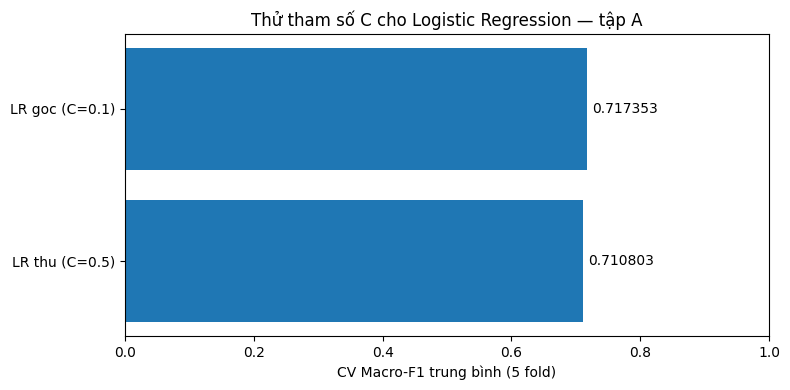


Đã xuất các file:
 - C:\doan\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-13_ThuThamSo_LR_Ly\ket_qua.xlsx
 - C:\doan\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-13_ThuThamSo_LR_Ly\ket_qua_tong_hop.csv
 - C:\doan\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-13_ThuThamSo_LR_Ly\diem_tung_fold.csv
 - C:\doan\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-13_ThuThamSo_LR_Ly\so_sanh_macro_f1.png


In [9]:
output_dir.mkdir(parents=True, exist_ok=True)
excel_path = output_dir / "ket_qua.xlsx"
summary_csv = output_dir / "ket_qua_tong_hop.csv"
fold_csv = output_dir / "diem_tung_fold.csv"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Nguoi thuc hien": "Ly",
    "Ngay thuc nghiem": "13/11/2026",
    "Du lieu": "data/processed/development.csv",
    "Tap dac trung": "A",
    "So mau": len(y),
    "So dac trung": X_a.shape[1],
    "So fold": N_FOLDS,
    "CV": "StratifiedKFold(shuffle=True, random_state=42)",
    "Chi so chinh": "CV Macro-F1 trung binh",
    "Tham so thay doi": "C: 0.1 -> 0.5",
    "sklearn_version": sklearn.__version__,
}])

results.to_csv(summary_csv, index=False, encoding="utf-8-sig")
fold_results.to_csv(fold_csv, index=False, encoding="utf-8-sig")
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    run_info.to_excel(writer, sheet_name="Thong tin thuc nghiem", index=False)
    pd.DataFrame([{"Cau hinh": name, **params} for name, params in configs.items()]).to_excel(
        writer, sheet_name="Cau hinh mo hinh", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(results["model"], results["cv_macro_f1"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("CV Macro-F1 trung bình (5 fold)")
ax.set_title("Thử tham số C cho Logistic Regression — tập A")
ax.bar_label(bars, fmt="%.6f", padding=4)
fig.tight_layout()
fig.savefig(image_path, dpi=180)
plt.show()

print("\nĐã xuất các file:")
for path in [excel_path, summary_csv, fold_csv, image_path]:
    print(" -", path)

## 4. Nhận xét

Khi tăng tham số C từ 0.1 lên 0.5, CV Macro-F1 của Logistic Regression giảm từ 0.717353 xuống 0.710803, tương ứng giảm 0.006550. Kết quả cho thấy cấu hình C=0.5 chưa cải thiện hiệu quả phân loại so với cấu hình ban đầu. Vì vậy, nhóm giữ nguyên C=0.1 vì cho kết quả tốt hơn trong thực nghiệm này.